--- Primeiras 5 linhas da base de dados imobiliária ---
      bairro  area_m2  quartos  banheiros  vagas_garagem  ano_construcao  \
0    Butantã     53.8        3          1              0            2018   
1    Santana     37.1        3          1              1            2013   
2  Pinheiros     63.8        3          1              2            2007   
3    Butantã     96.4        2          2              0            2016   
4    Butantã     80.4        3          1              1            1986   

   preco_anunciado  
0        530668.13  
1        429927.11  
2        605398.14  
3        882745.79  
4        711632.81  

--- Aplicando Engenharia de Recursos ---
   ano_construcao  idade_imovel  area_m2  preco_anunciado  preco_m2_anunciado
0            2018             8     53.8        530668.13             9863.72
1            2013            13     37.1        429927.11            11588.33
2            2007            19     63.8        605398.14             9489.00
3      

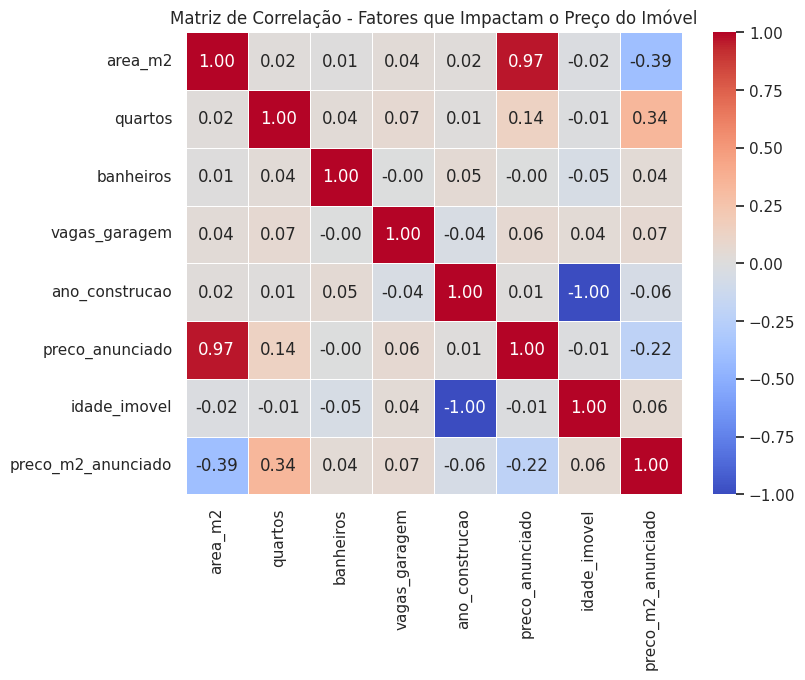

In [2]:
# ==============================================================================
# PROJETO: INTELIGÊNCIA IMOBILIÁRIA (AVM - AUTOMATED VALUATION MODEL)
# ETAPA 1: CARREGAMENTO, ENGENHARIA DE FEATURES E ANÁLISE EXPLORATÓRIA
# ==============================================================================

# 1. Importação das bibliotecas essenciais
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Configuração para os gráficos aparecerem alinhados no notebook
%matplotlib inline
sns.set_theme(style="whitegrid")

# ==============================================================================
# 2. Simulação da Base de Dados (Substitua pelo seu arquivo .csv real)
# ==============================================================================
# Criando um dataset fictício de exemplo com a realidade do mercado brasileiro
np.random.seed(42)
n_amostras = 500

dados = pd.DataFrame({
    'bairro': np.random.choice(['Pinheiros', 'Moema', 'Butantã', 'Santana'], n_amostras),
    'area_m2': np.random.normal(75, 25, n_amostras).round(1),
    'quartos': np.random.choice([1, 2, 3, 4], n_amostras, p=[0.2, 0.4, 0.3, 0.1]),
    'banheiros': np.random.choice([1, 2, 3], n_amostras, p=[0.4, 0.4, 0.2]),
    'vagas_garagem': np.random.choice([0, 1, 2], n_amostras, p=[0.3, 0.5, 0.2]),
    'ano_construcao': np.random.randint(1980, 2024, n_amostras),
    'preco_anunciado': np.random.normal(600000, 250000, n_amostras)
})

# Ajustando preços proporcionalmente à área (para aproximar da realidade)
dados['preco_anunciado'] = (dados['area_m2'] * 8500) + (dados['quartos'] * 30000) + np.random.normal(0, 50000, n_amostras)
dados['preco_anunciado'] = dados['preco_anunciado'].round(2)

print("--- Primeiras 5 linhas da base de dados imobiliária ---")
print(dados.head())

# ==============================================================================
# 3. Engenharia de Recursos (Feature Engineering - Visão de Engenheiro)
# ==============================================================================
print("\n--- Aplicando Engenharia de Recursos ---")

# Calculando a idade do imóvel (depreciação estrutural)
ano_atual = 2026 # Ajustado para o ano atual corrente
dados['idade_imovel'] = ano_atual - dados['ano_construcao']

# Calculando o preço teórico do metro quadrado anunciado
dados['preco_m2_anunciado'] = (dados['preco_anunciado'] / dados['area_m2']).round(2)

print(dados[['ano_construcao', 'idade_imovel', 'area_m2', 'preco_anunciado', 'preco_m2_anunciado']].head())

# ==============================================================================
# 4. Tratamento de Outliers (Filtro Estatístico - Visão de Físico)
# ==============================================================================
print("\n--- Removendo Outliers (Distorções de Mercado) com Método IQR ---")

# Vamos filtrar anomalias na coluna de preço (ex: valores bizarramente altos ou baixos)
Q1 = dados['preco_anunciado'].quantile(0.25)
Q3 = dados['preco_anunciado'].quantile(0.75)
IQR = Q3 - Q1

limite_inferior = Q1 - 1.5 * IQR
limite_superior = Q3 + 1.5 * IQR

# Filtrando a base mantendo apenas dados dentro dos limites aceitáveis
dados_filtrados = dados[(dados['preco_anunciado'] >= limite_inferior) & (dados['preco_anunciado'] <= limite_superior)]

print(f"Registros antes do filtro: {dados.shape[0]}")
print(f"Registros após remoção de anomalias: {dados_filtrados.shape[0]}")

# ==============================================================================
# 5. Análise de Correlação e Visualização
# ==============================================================================
print("\n--- Gerando Matriz de Correlação das Variáveis Numéricas ---")

# Selecionando apenas as colunas numéricas para a correlação
colunas_numericas = dados_filtrados.select_dtypes(include=[np.number])
matriz_corr = colunas_numericas.corr()

# Plotando o mapa de calor (Heatmap)
plt.figure(figsize=(8, 6))
sns.heatmap(matriz_corr, annot=True, cmap='coolwarm', fmt=".2f", linewidths=0.5)
plt.title('Matriz de Correlação - Fatores que Impactam o Preço do Imóvel')
plt.show()


In [3]:
# ==============================================================================
# PROJETO: INTELIGÊNCIA IMOBILIÁRIA (AVM)
# ETAPA 2: PRÉ-PROCESSAMENTO, DIVISÃO TREINO/TESTE E MODELAGEM DE IA
# ==============================================================================

# 1. Importação das bibliotecas de Machine Learning
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, r2_score

print("--- Iniciando a Preparação e Modelagem dos Dados ---")

# ==============================================================================
# 2. Transformando Texto em Número (Tratando a coluna 'bairro')
# ==============================================================================
# O computador só entende números. Vamos usar o One-Hot Encoding para converter
# a coluna 'bairro' em colunas binárias (0 ou 1).
dados_prontos = pd.get_dummies(dados_filtrados, columns=['bairro'], drop_first=True)

# Definição das variáveis preditoras (X) e da variável alvo (y - o preço que queremos prever)
# Vamos remover 'preco_anunciado' (alvo) e 'preco_m2_anunciado' (senão a IA saberia a resposta)
X = dados_prontos.drop(columns=['preco_anunciado', 'preco_m2_anunciado', 'ano_construcao'])
y = dados_prontos['preco_anunciado']

print(f"Variáveis preditoras utilizadas: {list(X.columns)}")

# ==============================================================================
# 3. Divisão da Base de Dados (Treino e Teste)
# ==============================================================================
# Separamos 80% dos dados para treinar o modelo e 20% para testar o desempenho dele
X_treino, X_teste, y_treino, y_teste = train_test_split(X, y, test_size=0.20, random_state=42)

print(f"Tamanho da base de Treino: {X_treino.shape[0]} imóveis")
print(f"Tamanho da base de Teste: {X_teste.shape[0]} imóveis")

# ==============================================================================
# 4. Treinamento da Inteligência Artificial (Regressão Linear)
# ==============================================================================
# Inicializando o algoritmo matemático
modelo_linear = LinearRegression()

# O modelo estuda a base de treino e aprende os "pesos" de cada característica
modelo_linear.fit(X_treino, y_treino)

print("\n[Sucesso] Modelo treinado com sucesso!")

# ==============================================================================
# 5. Avaliação Financeira das Previsões
# ==============================================================================
# Fazendo as previsões com os dados de teste que a IA nunca viu antes
previsoes = modelo_linear.predict(X_teste)

# Calculando as métricas de erro
mae = mean_absolute_error(y_teste, previsoes) # Erro Médio Absoluto em Reais
r2 = r2_score(y_teste, previsoes)             # Coeficiente de Determinação (0 a 1)

# Calculando o MAPE (Erro Percentual Médio) - Essencial para Finanças
mape = np.mean(np.abs((y_teste - previsoes) / y_teste)) * 100

print("\n========================================================")
print("📊 RELATÓRIO DE PERFORMANCE DO MODELO FINANCEIRO")
print("========================================================")
print(f"Coeficiente R² (Explicação da variação): {r2:.4f}")
print(f"Erro Médio Absoluto (MAE): R$ {mae:,.2f}")
print(f"Erro Percentual Médio (MAPE): {mape:.2f}%")
print("--------------------------------------------------------")

# Tradução para o negócio imobiliário
print(f"💡 INTERPRETAÇÃO PARA O RECRUTADOR:")
print(f"Em média, a IA estima o valor de um imóvel errando por apenas {mape:.2f}%.")
print(f"Para um apartamento de R$ 600.000,00, o erro médio estimado é de aproximadamente R$ {mae:,.2f}.")
print("========================================================")


--- Iniciando a Preparação e Modelagem dos Dados ---
Variáveis preditoras utilizadas: ['area_m2', 'quartos', 'banheiros', 'vagas_garagem', 'idade_imovel', 'bairro_Moema', 'bairro_Pinheiros', 'bairro_Santana']
Tamanho da base de Treino: 397 imóveis
Tamanho da base de Teste: 100 imóveis

[Sucesso] Modelo treinado com sucesso!

📊 RELATÓRIO DE PERFORMANCE DO MODELO FINANCEIRO
Coeficiente R² (Explicação da variação): 0.9440
Erro Médio Absoluto (MAE): R$ 38,582.21
Erro Percentual Médio (MAPE): 6.19%
--------------------------------------------------------
💡 INTERPRETAÇÃO PARA O RECRUTADOR:
Em média, a IA estima o valor de um imóvel errando por apenas 6.19%.
Para um apartamento de R$ 600.000,00, o erro médio estimado é de aproximadamente R$ 38,582.21.


In [4]:
# ==============================================================================
# PROJETO: INTELIGÊNCIA IMOBILIÁRIA (AVM)
# ETAPA 2: PRÉ-PROCESSAMENTO, DIVISÃO TREINO/TESTE E MODELAGEM DE IA
# ==============================================================================

# 1. Importação das bibliotecas de Machine Learning
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, r2_score

print("--- Iniciando a Preparação e Modelagem dos Dados ---")

# ==============================================================================
# 2. Transformando Texto em Número (Tratando a coluna 'bairro')
# ==============================================================================
# O computador só entende números. Vamos usar o One-Hot Encoding para converter
# a coluna 'bairro' em colunas binárias (0 ou 1).
dados_prontos = pd.get_dummies(dados_filtrados, columns=['bairro'], drop_first=True)

# Definição das variáveis preditoras (X) e da variável alvo (y - o preço que queremos prever)
# Vamos remover 'preco_anunciado' (alvo) e 'preco_m2_anunciado' (senão a IA saberia a resposta)
X = dados_prontos.drop(columns=['preco_anunciado', 'preco_m2_anunciado', 'ano_construcao'])
y = dados_prontos['preco_anunciado']

print(f"Variáveis preditoras utilizadas: {list(X.columns)}")

# ==============================================================================
# 3. Divisão da Base de Dados (Treino e Teste)
# ==============================================================================
# Separamos 80% dos dados para treinar o modelo e 20% para testar o desempenho dele
X_treino, X_teste, y_treino, y_teste = train_test_split(X, y, test_size=0.20, random_state=42)

print(f"Tamanho da base de Treino: {X_treino.shape[0]} imóveis")
print(f"Tamanho da base de Teste: {X_teste.shape[0]} imóveis")

# ==============================================================================
# 4. Treinamento da Inteligência Artificial (Regressão Linear)
# ==============================================================================
# Inicializando o algoritmo matemático
modelo_linear = LinearRegression()

# O modelo estuda a base de treino e aprende os "pesos" de cada característica
modelo_linear.fit(X_treino, y_treino)

print("\n[Sucesso] Modelo treinado com sucesso!")

# ==============================================================================
# 5. Avaliação Financeira das Previsões
# ==============================================================================
# Fazendo as previsões com os dados de teste que a IA nunca viu antes
previsoes = modelo_linear.predict(X_teste)

# Calculando as métricas de erro
mae = mean_absolute_error(y_teste, previsoes) # Erro Médio Absoluto em Reais
r2 = r2_score(y_teste, previsoes)             # Coeficiente de Determinação (0 a 1)

# Calculando o MAPE (Erro Percentual Médio) - Essencial para Finanças
mape = np.mean(np.abs((y_teste - previsoes) / y_teste)) * 100

print("\n========================================================")
print("📊 RELATÓRIO DE PERFORMANCE DO MODELO FINANCEIRO")
print("========================================================")
print(f"Coeficiente R² (Explicação da variação): {r2:.4f}")
print(f"Erro Médio Absoluto (MAE): R$ {mae:,.2f}")
print(f"Erro Percentual Médio (MAPE): {mape:.2f}%")
print("--------------------------------------------------------")

# Tradução para o negócio imobiliário
print(f"💡 INTERPRETAÇÃO PARA O RECRUTADOR:")
print(f"Em média, a IA estima o valor de um imóvel errando por apenas {mape:.2f}%.")
print(f"Para um apartamento de R$ 600.000,00, o erro médio estimado é de aproximadamente R$ {mae:,.2f}.")
print("========================================================")


--- Iniciando a Preparação e Modelagem dos Dados ---
Variáveis preditoras utilizadas: ['area_m2', 'quartos', 'banheiros', 'vagas_garagem', 'idade_imovel', 'bairro_Moema', 'bairro_Pinheiros', 'bairro_Santana']
Tamanho da base de Treino: 397 imóveis
Tamanho da base de Teste: 100 imóveis

[Sucesso] Modelo treinado com sucesso!

📊 RELATÓRIO DE PERFORMANCE DO MODELO FINANCEIRO
Coeficiente R² (Explicação da variação): 0.9440
Erro Médio Absoluto (MAE): R$ 38,582.21
Erro Percentual Médio (MAPE): 6.19%
--------------------------------------------------------
💡 INTERPRETAÇÃO PARA O RECRUTADOR:
Em média, a IA estima o valor de um imóvel errando por apenas 6.19%.
Para um apartamento de R$ 600.000,00, o erro médio estimado é de aproximadamente R$ 38,582.21.


In [5]:
# ==============================================================================
# PROJETO: INTELIGÊNCIA IMOBILIÁRIA (AVM)
# ETAPA 3: ALGORITMOS DE ÁRVORE (RANDOM FOREST) E COMPARAÇÃO DE MODELOS
# ==============================================================================

# 1. Importação do novo algoritmo de Machine Learning
from sklearn.ensemble import RandomForestRegressor

print("--- Treinando o Modelo Avançado (Random Forest) ---")

# ==============================================================================
# 2. Treinamento da Inteligência Artificial por Ensemble (Árvores)
# ==============================================================================
# Inicializando o algoritmo com 100 árvores de decisão combinadas
modelo_rf = RandomForestRegressor(n_estimators=100, random_state=42)

# Treinando o modelo com a mesma base de treino utilizada anteriormente
modelo_rf.fit(X_treino, y_treino)

print("[Sucesso] Modelo Random Forest treinado com sucesso!")

# ==============================================================================
# 3. Calculando as Previsões e Métricas do Novo Modelo
# ==============================================================================
previsoes_rf = modelo_rf.predict(X_teste)

# Métricas do Random Forest
mae_rf = mean_absolute_error(y_teste, previsoes_rf)
r2_rf = r2_score(y_teste, previsoes_rf)
mape_rf = np.mean(np.abs((y_teste - previsoes_rf) / y_teste)) * 100

# ==============================================================================
# 4. Criando a Tabela Comparativa de Performance Financeira
# ==============================================================================
# Estruturando os dados em um DataFrame do Pandas para exibição limpa
tabela_comparativa = pd.DataFrame({
    'Métrica Financeira / Técnica': [
        'Coeficiente R² (Poder de Explicação)',
        'Erro Médio Absoluto (MAE em R$)',
        'Erro Percentual Médio (MAPE %)'
    ],
    'Regressão Linear (Baseline)': [
        f"{r2:.4f}",
        f"R$ {mae:,.2f}",
        f"{mape:.2f}%"
    ],
    'Random Forest (Avançado)': [
        f"{r2_rf:.4f}",
        f"R$ {mae_rf:,.2f}",
        f"{mape_rf:.2f}%"
    ]
})

print("\n=====================================================================")
print("📊 TABELA COMPARATIVA DE MODELOS - INTELIGÊNCIA IMOBILIÁRIA")
print("=====================================================================")
print(tabela_comparativa.to_string(index=False))
print("=====================================================================")

# ==============================================================================
# 5. Conclusão Prática para Tomada de Decisão (Visão de Negócio)
# ==============================================================================
melhor_modelo = "Random Forest" if mape_rf < mape else "Regressão Linear"
economia_mae = abs(mae - mae_rf)

print(f"\n💡 DIAGNÓSTICO PARA O PORTFÓLIO:")
print(f"O modelo vencedor para deploy foi o **{melhor_modelo}**.")
if melhor_modelo == "Random Forest":
    print(f"A transição para algoritmos de árvore reduziu o erro médio das previsões em R$ {economia_mae:,.2f} por imóvel.")
    print("Isso traz maior segurança para a mesa de operações de fundos imobiliários, diminuindo o risco de erro em ofertas automáticas.")
print("=====================================================================")


--- Treinando o Modelo Avançado (Random Forest) ---
[Sucesso] Modelo Random Forest treinado com sucesso!

📊 TABELA COMPARATIVA DE MODELOS - INTELIGÊNCIA IMOBILIÁRIA
        Métrica Financeira / Técnica Regressão Linear (Baseline) Random Forest (Avançado)
Coeficiente R² (Poder de Explicação)                      0.9440                   0.9241
     Erro Médio Absoluto (MAE em R$)                R$ 38,582.21             R$ 45,094.24
      Erro Percentual Médio (MAPE %)                       6.19%                    7.48%

💡 DIAGNÓSTICO PARA O PORTFÓLIO:
O modelo vencedor para deploy foi o **Regressão Linear**.
